In [1]:
import sys
sys.path.append("..")

from sklearn.model_selection import GroupShuffleSplit
from src.data import load_cmapss

df = load_cmapss("../data/train_FD001.txt")
df["RUL"] = df.groupby("unit")["cycle"].transform("max") - df["cycle"]

constantes = ["setting_3", "s1", "s5", "s10", "s16", "s18", "s19"]
features = ["setting_1", "setting_2", "setting_3"] + [f"s{i}" for i in range(1, 22)]
utiles = [c for c in features if c not in constantes]

X = df[utiles]
y = df["RUL"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(X, y, groups=df["unit"]))

X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

In [2]:
unidades_train = set(df.iloc[train_idx]["unit"])
unidades_val = set(df.iloc[val_idx]["unit"])

print(len(unidades_train), len(unidades_val))   # 80 20
print(unidades_train & unidades_val)            # set() -> vacío
print(X_train.shape, X_val.shape)

80 20
set()
(16561, 17) (4070, 17)


In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

def evaluar(modelo, nombre):
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    mae = mean_absolute_error(y_val, pred)
    print(f"{nombre}: RMSE={rmse:.1f}  MAE={mae:.1f}")

evaluar(DummyRegressor(strategy="mean"), "Baseline (media)")
evaluar(LinearRegression(), "Regresión lineal")

Baseline (media): RMSE=65.7  MAE=55.4
Regresión lineal: RMSE=38.1  MAE=30.1


In [4]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

evaluar(RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1), "Random Forest")
evaluar(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42), "XGBoost")

Random Forest: RMSE=35.3  MAE=25.8
XGBoost: RMSE=35.3  MAE=25.9


In [5]:
def evaluar(modelo, nombre, y_tr, y_va):
    modelo.fit(X_train, y_tr)
    pred = modelo.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_va, pred))
    mae = mean_absolute_error(y_va, pred)
    print(f"{nombre}: RMSE={rmse:.1f}  MAE={mae:.1f}")

y_train_c = y_train.clip(upper=125)
y_val_c = y_val.clip(upper=125)

evaluar(DummyRegressor(strategy="mean"), "Baseline (media)", y_train_c, y_val_c)
evaluar(LinearRegression(), "Regresión lineal", y_train_c, y_val_c)
evaluar(RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1), "Random Forest", y_train_c, y_val_c)
evaluar(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42), "XGBoost", y_train_c, y_val_c)

Baseline (media): RMSE=41.7  MAE=36.9
Regresión lineal: RMSE=20.4  MAE=16.5
Random Forest: RMSE=17.0  MAE=12.3
XGBoost: RMSE=16.9  MAE=12.3


In [6]:
import pandas as pd

lin = LinearRegression().fit(X_train, y_train_c)
rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1).fit(X_train, y_train_c)
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42).fit(X_train, y_train_c)

test = load_cmapss("../data/test_FD001.txt")
ultimo = test.loc[test.groupby("unit")["cycle"].idxmax()]
rul_real_raw = pd.read_csv("../data/RUL_FD001.txt", header=None)[0]

for nombre, m in [("Regresión lineal", lin), ("Random Forest", rf), ("XGBoost", xgb)]:
    pred = m.predict(ultimo[utiles])
    rmse = np.sqrt(mean_squared_error(rul_real_raw, pred))
    mae = mean_absolute_error(rul_real_raw, pred)
    print(f"{nombre} (test oficial, RUL real): RMSE={rmse:.1f}  MAE={mae:.1f}")

Regresión lineal (test oficial, RUL real): RMSE=21.9  MAE=17.6
Random Forest (test oficial, RUL real): RMSE=18.1  MAE=13.0
XGBoost (test oficial, RUL real): RMSE=18.5  MAE=13.1


In [7]:
print(ultimo.shape, rul_real_raw.shape)   # (100, 26) (100,)

(100, 26) (100,)


In [8]:
import pandas as pd
from sklearn.model_selection import GroupKFold

mini = pd.DataFrame({"unit": [1,1,2,2,3,3,4,4], "x": range(8)})

for i, (tr, va) in enumerate(GroupKFold(n_splits=2).split(mini, groups=mini["unit"])):
    print(f"fold {i}: train={sorted(mini.iloc[tr]['unit'].unique())}  val={sorted(mini.iloc[va]['unit'].unique())}")

fold 0: train=[np.int64(1), np.int64(3)]  val=[np.int64(2), np.int64(4)]
fold 1: train=[np.int64(2), np.int64(4)]  val=[np.int64(1), np.int64(3)]


In [9]:
from sklearn.model_selection import GroupKFold, cross_val_score

y_c = df["RUL"].clip(upper=125)
cv = GroupKFold(n_splits=5)

for depth in [3, 4, 6]:
    for lr in [0.05, 0.1]:
        modelo = XGBRegressor(n_estimators=300, learning_rate=lr, max_depth=depth, random_state=42)
        scores = cross_val_score(modelo, X, y_c, groups=df["unit"], cv=cv,
                                 scoring="neg_root_mean_squared_error")
        print(f"depth={depth} lr={lr}: RMSE={-scores.mean():.2f} (±{scores.std():.2f})")

depth=3 lr=0.05: RMSE=18.43 (±1.56)
depth=3 lr=0.1: RMSE=18.44 (±1.58)
depth=4 lr=0.05: RMSE=18.38 (±1.57)
depth=4 lr=0.1: RMSE=18.51 (±1.58)
depth=6 lr=0.05: RMSE=18.49 (±1.61)
depth=6 lr=0.1: RMSE=18.86 (±1.57)


In [10]:
sensores = [c for c in utiles if not c.startswith("setting")]

roll = (df.groupby("unit")[sensores]
          .rolling(window=10, min_periods=1).mean()
          .reset_index(level=0, drop=True))
roll.columns = [f"{c}_m10" for c in sensores]
X2 = pd.concat([df[utiles], roll], axis=1)

print(X2.shape)

(20631, 32)


In [11]:
modelo = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42)
for nombre, Xi in [("sin ventana", X), ("con ventana", X2)]:
    scores = cross_val_score(modelo, Xi, y_c, groups=df["unit"], cv=cv,
                             scoring="neg_root_mean_squared_error")
    print(f"{nombre}: RMSE={-scores.mean():.2f} (±{scores.std():.2f})")

sin ventana: RMSE=18.38 (±1.57)
con ventana: RMSE=18.44 (±1.73)


In [12]:
for w in [5, 20, 30]:
    roll = (df.groupby("unit")[sensores]
              .rolling(window=w, min_periods=1).mean()
              .reset_index(level=0, drop=True))
    roll.columns = [f"{c}_m{w}" for c in sensores]
    Xw = pd.concat([df[utiles], roll], axis=1)
    scores = cross_val_score(modelo, Xw, y_c, groups=df["unit"], cv=cv,
                             scoring="neg_root_mean_squared_error")
    print(f"ventana {w}: RMSE={-scores.mean():.2f} (±{scores.std():.2f})")

ventana 5: RMSE=18.14 (±1.75)
ventana 20: RMSE=18.40 (±1.56)
ventana 30: RMSE=18.18 (±1.28)


In [13]:
modelo = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42)
base = cross_val_score(modelo, X, y_c, groups=df["unit"], cv=cv, scoring="neg_root_mean_squared_error")

roll = (df.groupby("unit")[sensores].rolling(window=5, min_periods=1).mean()
          .reset_index(level=0, drop=True))
roll.columns = [f"{c}_m5" for c in sensores]
X5 = pd.concat([df[utiles], roll], axis=1)
vent = cross_val_score(modelo, X5, y_c, groups=df["unit"], cv=cv, scoring="neg_root_mean_squared_error")

dif = base - vent
print(dif.round(2), dif.mean().round(2))

[-0.17  0.14 -0.49 -0.17 -0.47] -0.23


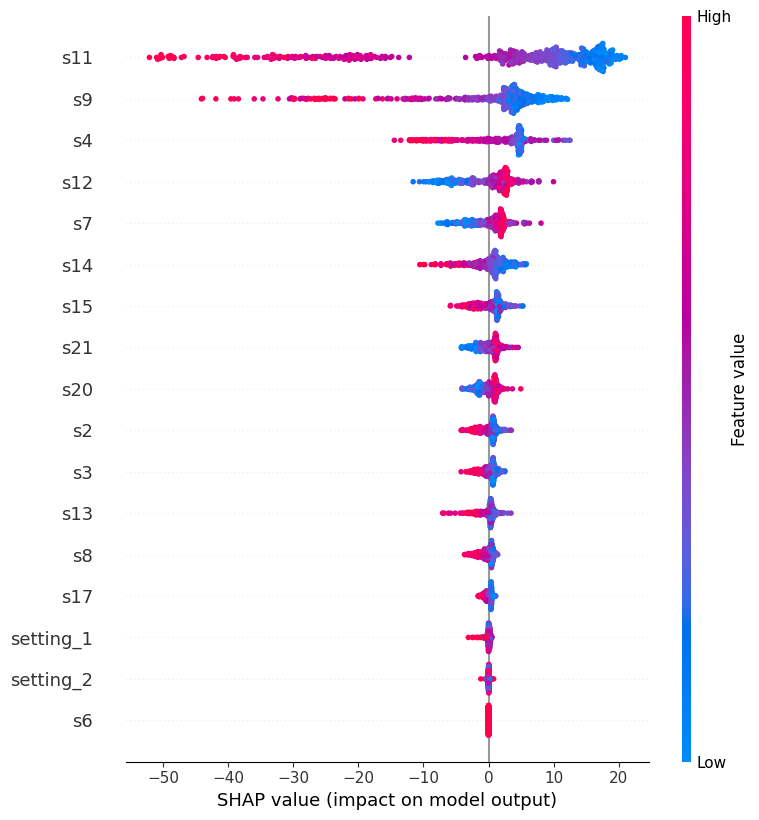

In [15]:
import shap

muestra = X_val.sample(500, random_state=0)
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(muestra)
shap.summary_plot(sv, muestra)

In [16]:
pred = rf.predict(ultimo[utiles])
real = rul_real_raw.values
H, C_FALLA, C_MANT = 30, 100, 10

for umbral in range(20, 91, 10):
    interviene = pred < umbral
    fallas = (~interviene) & (real < H)
    costo = C_MANT * interviene.sum() + C_FALLA * fallas.sum()
    print(f"umbral={umbral}: intervenciones={interviene.sum()}  fallas={fallas.sum()}  costo={costo}")

print("Nunca intervenir:", C_FALLA * (real < H).sum())
print("Intervenir siempre:", C_MANT * len(real))

umbral=20: intervenciones=10  fallas=15  costo=1600
umbral=30: intervenciones=19  fallas=7  costo=890
umbral=40: intervenciones=22  fallas=5  costo=720
umbral=50: intervenciones=27  fallas=4  costo=670
umbral=60: intervenciones=34  fallas=2  costo=540
umbral=70: intervenciones=39  fallas=1  costo=490
umbral=80: intervenciones=45  fallas=0  costo=450
umbral=90: intervenciones=48  fallas=0  costo=480
Nunca intervenir: 2500
Intervenir siempre: 1000


In [17]:
for c_falla in [30, 50, 100, 200]:
    mejor = min(
        (C_MANT * (pred < u).sum() + c_falla * ((pred >= u) & (real < H)).sum(), u)
        for u in range(20, 91, 10)
    )
    print(f"falla={c_falla}: mejor umbral={mejor[1]}, costo={mejor[0]}")

falla=30: mejor umbral=40, costo=370
falla=50: mejor umbral=60, costo=440
falla=100: mejor umbral=80, costo=450
falla=200: mejor umbral=80, costo=450
